# Workflow 5: windows and restabilisation (SQ1 × SQ2)

**Group 17, Theme 17 (Track D), Minês + Bruno.** This notebook documents WF5: what was computed, how, and
what it shows. It **only reads saved runs** (it never re-runs the model).

| Task | Who | Section |
|---|---|---|
| Window analysis on S3 + Elec2: 1,000-sample windows, Jaccard + weighted τ (consecutive, first vs last) | Minês | 2 |
| Same on S1, S2, S4 + last window before the drift vs last window | Bruno | 3 |
| Figure 2b: first vs last window relevance per feature (S3 vs S1 vs Elec2) | Minês + Bruno | 4 |
| Restabilisation time after drift (weighted τ at lag 200, 10th percentile, 3 in a row) | Minês + Bruno | 5 |

## 0. Setup

Before running this notebook, from the repository root:
```
python run_relevance.py --config configs/protocol/s3_gauss_stationary.json --variants ref --outdir results_wf5 --jobs 4
python wf5_windows/analyze_wf5.py
python wf5_windows/figure2b.py
```

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

ROOT = Path.cwd()
if not (ROOT / "wf5_windows").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from wf5_windows.windows import lag_wtau, clean_mask, WIDTH, LAG
from wf5_windows.analyze_wf5 import load_runs, STREAMS

RES = ROOT / "wf5_windows" / "results"
per_run = pd.read_csv(RES / "windows_per_run.csv")
pairs = pd.read_csv(RES / "consecutive_pairs.csv")
means = pd.read_csv(RES / "window_means.csv")
restab = pd.read_csv(RES / "restab_per_run.csv")
FIRST, LAST, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
pd.set_option("display.precision", 3)
print({s: STREAMS[s][0] for s in STREAMS})

{'S3': 'results_wf5/s3_gauss_stationary/ref', 'Elec2': 'results_relevance/wf1_elec2_nodate', 'S1': 'results_wf2/s1_gauss_abrupt/ref', 'S2': 'results_wf2/s2_gauss_gradual/ref', 'S4': 'results_wf2/s4_sea_drift/ref'}


## 1. What is measured

**R1 = G**, the model's global relevance weights, saved every 50 samples (a *checkpoint*). G is
recomputed from the last 200 samples, floored at 0.2 and scaled so the maximum is 1.

1. **Windows.** The stream is cut into non-overlapping 1,000-sample windows (20 on synthetic streams, 10 on
   Elec2). A window's relevance is the **mean of G over its clean checkpoints** (the 200-sample buffer holds
   one concept only; so the first window starts at t = 200).
2. **Comparing two windows.**
   - **Top-k Jaccard**: |A ∩ B| / |A ∪ B| of the k most relevant features. 1 = same set, 0 = disjoint.
   - **Weighted τ** (`scipy.stats.weightedtau`): rank agreement over *all* features, where disagreements
     near the top cost more. 1 = same order, 0 = unrelated, negative = reversed.
3. **Restabilisation.** s(t) = weighted τ between G at t and at t − 200. Threshold = 10th percentile of s
   before the drift. After the drift, find the trough (lowest s within 1,000 samples); restabilised = first
   time from the trough on that s ≥ threshold for 3 checkpoints in a row.

k = 3 on S1, S2, S3 and Elec2; k = 2 on S4.

## 2. Window analysis on S3 and Elec2 (Minês)

**S3** is the stationary control (S1's first concept only: x0, x1, x2 relevant, nothing changes; 10 seeds).
**Elec2** is the real stream (first 10,000 samples, real order, `date` dropped; one run, so no CI).

### 2.1 Summary per stream

In [2]:
cols = ["first_last_jaccard", "first_last_wtau", "consec_jaccard_mean", "consec_jaccard_min",
        "consec_wtau_mean", "consec_wtau_min"]
sub = per_run[per_run.stream.isin(["S3", "Elec2"])]
display(sub.groupby("stream", sort=False)[cols].agg(["mean", "std"]).round(3))
display(sub.groupby("stream", sort=False)[["topk_first", "topk_last"]].agg(lambda x: x.value_counts().to_dict()))

first_last_jaccard      first_last_wtau        consec_jaccard_mean  \
                     mean  std            mean    std                mean   
stream                                                                      
S3                    1.0  0.0            0.59  0.114               1.000   
Elec2                 1.0  NaN            1.00    NaN               0.778   

            consec_jaccard_min      consec_wtau_mean        consec_wtau_min  \
        std               mean  std             mean    std            mean   
stream                                                                        
S3      0.0                1.0  0.0            0.637  0.019           0.439   
Elec2   NaN                0.5  NaN            0.964    NaN           0.920   

               
          std  
stream         
S3      0.034  
Elec2     NaN

,topk_first,topk_last
stream,,
S3,"{'{x0,x1,x2}': 10}","{'{x0,x1,x2}': 10}"
Elec2,"{'{period,nswprice,nswdemand}': 1}","{'{period,nswprice,nswdemand}': 1}"


### 2.2 Relevance per window over time

Rows = features, columns = 1,000-sample windows, colour = mean G in that window. S3 is averaged over its 10 seeds; Elec2 is its single run, with every value written in the cell.

In [ ]:
# Mean relevance per feature (rows) and 1,000-sample window (columns).
# S3: mean over the 10 seeds; Elec2: its single run, with every value written in the cell.
fig, axes = plt.subplots(2, 1, figsize=(11, 7.2), gridspec_kw=dict(height_ratios=[10, 7]), layout="constrained")
for ax, name in zip(axes, ["S3", "Elec2"]):
    g = means[means.stream == name]
    order = list(dict.fromkeys(g.feature))
    M = g.groupby(["feature", "window"]).relevance.mean().unstack().reindex(order)
    im = ax.imshow(M.values, aspect="auto", cmap="Blues", vmin=0.2, vmax=1)
    n_w = M.shape[1]
    ax.set_xticks(np.arange(-0.5, n_w, 1), minor=True); ax.set_yticks(np.arange(-0.5, len(order), 1), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
    ax.tick_params(length=0)
    step = 2 if n_w > 10 else 1
    ax.set_xticks(range(0, n_w, step), [f"{w}k" for w in range(0, n_w, step)])
    ax.set_yticks(range(len(order)), order)
    for s in ax.spines.values(): s.set_visible(False)
    if name == "Elec2":
        for (i, j), v in np.ndenumerate(M.values):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.65 else "#0b0b0b")
    title = ("S3 stationary: mean over 10 seeds (x0, x1, x2 truly relevant)" if name == "S3"
             else "Elec2 (one run, real order)")
    ax.set_title(title, loc="left", fontsize=10)
for ax in axes: ax.set_xlabel("window start (samples)")
fig.colorbar(im, ax=axes, shrink=0.6, label="mean G in window (0.2 = floor)")
plt.show()

### 2.3 Consecutive windows

Jaccard and weighted τ between each window and the next one.

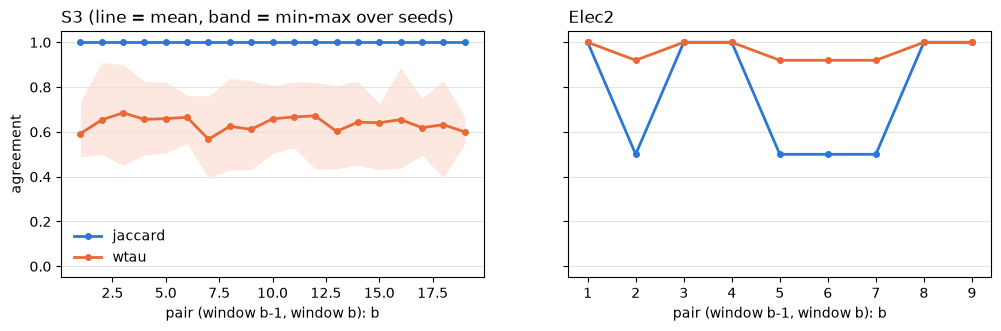

,190,191,192,193,194,195,196,197,198
win_a,0.0,1.00,2.0,3.0,4.00,5.00,6.00,7.0,8.0
win_b,1.0,2.00,3.0,4.0,5.00,6.00,7.00,8.0,9.0
jaccard,1.0,0.50,1.0,1.0,0.50,0.50,0.50,1.0,1.0
wtau,1.0,0.92,1.0,1.0,0.92,0.92,0.92,1.0,1.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, name in zip(axes, ["S3", "Elec2"]):
    p = pairs[pairs.stream == name]
    for metric, col in (("jaccard", FIRST), ("wtau", LAST)):
        g = p.groupby("win_b")[metric]
        ax.plot(g.mean().index, g.mean().values, "-o", ms=4, lw=2, color=col, label=metric)
        if p.seed.nunique() > 1:
            ax.fill_between(g.mean().index, g.min().values, g.max().values, color=col, alpha=0.15, lw=0)
    ax.set_title(name + (" (line = mean, band = min-max over seeds)" if p.seed.nunique() > 1 else ""), loc="left")
    ax.set_xlabel("pair (window b-1, window b): b"); ax.grid(axis="y", color=GRID); ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("agreement"); axes[0].legend(frameon=False)
plt.show()
display(pairs[pairs.stream == "Elec2"][["win_a", "win_b", "jaccard", "wtau"]].round(3).T)

**What to look for.**
- On S3, is the top-3 set the same in every window and every seed? What does that say about H1 (stability)?
- On S3, why is weighted τ (~0.6) much lower than Jaccard (1)? Hint: look at the values of x3–x9 in the
  heat map. What does the 0.2 floor do to their order?
- On Elec2, which features are always in the top-3, and which one keeps changing? Look at the heat map:
  are `day` and `period` really different, or nearly tied?
- Elec2's first and last windows have the same top-3. Does that mean Elec2's relevance is stable inside the run?
- Compare with WF1 (Jaccard at lag 200: Elec2 0.70 vs shuffled 0.88). Do 1,000-sample windows tell the same story?

> **Conclusion (section 2: S3 and Elec2).**
> - **S3 is perfectly stable at the window scale.** The top-3 set is {x0, x1, x2} in every 1,000-sample window
>   of every seed: Jaccard = 1 for all consecutive pairs and for first vs last (10/10 seeds). This supports H1.
> - **Weighted τ is much lower (0.59 ± 0.11 first vs last; 0.64 ± 0.02 between consecutive windows), but this
>   is not instability of the relevant features.** The heat map shows x3–x9 all sitting at the 0.2 floor, so
>   their relative order is random and drags τ down. This matches τ-b ≈ 0.47 at lag 200 in the S3 run summary.
>   Top-k Jaccard is therefore the meaningful stability measure; τ over all features mostly measures the noisy tail.
> - **Elec2 has a stable core with churn at rank 3.** `nswprice` is the most relevant feature in every window
>   (≈ 1.00) and `nswdemand` is second (0.27–0.50). The third place alternates between `period` and `day`, whose
>   window means are nearly tied (0.21–0.32), so 4 of 9 consecutive pairs have Jaccard 0.5 (wτ 0.92).
> - **"First = last" on Elec2 (Jaccard 1, wτ 1) hides this within-run churn**, so the first-vs-last comparison
>   alone would overstate Elec2's stability. This is consistent with WF1 (Elec2 less stable than its shuffled
>   copies at lag 200). With one real order there is no CI, and a near-tie at rank 3 cannot be called real
>   temporal change from this analysis alone.

## 3. Window analysis on S1, S2 and S4 (Bruno)

- **S1**: relevant set {0,1,2} → {5,6,7} at 10,000, abrupt.
- **S2**: same swap, gradual (transition 9,500–10,500).
- **S4**: SEA; the label threshold changes at 10,000 but the relevant set {0,1} does **not** (negative control).

The *last pre-drift window* is the last window that ends before the transition starts: 9,000–10,000 on
S1/S4, 8,000–9,000 on S2. Consecutive pairs that overlap the drift are counted separately (`crossing_*`).

In [5]:
cols = ["first_last_jaccard", "first_last_wtau", "pre_last_jaccard", "pre_last_wtau",
        "consec_jaccard_min", "consec_wtau_mean", "crossing_jaccard_min", "crossing_wtau_min"]
sub = per_run[per_run.stream.isin(["S1", "S2", "S4"])]
display(sub.groupby("stream", sort=False)[cols].agg(["mean", "std"]).round(3).T)
display(sub.groupby("stream", sort=False)[["topk_pre", "topk_last"]].agg(lambda x: x.value_counts().to_dict()))

stream                        S1     S2     S4
first_last_jaccard   mean  0.000  0.000  1.000
                     std   0.000  0.000  0.000
first_last_wtau      mean -0.228 -0.228  0.673
                     std   0.222  0.222  0.423
pre_last_jaccard     mean  0.000  0.000  1.000
                     std   0.000  0.000  0.000
pre_last_wtau        mean -0.352 -0.356  0.673
                     std   0.243  0.180  0.423
consec_jaccard_min   mean  1.000  1.000  1.000
                     std   0.000  0.000  0.000
consec_wtau_mean     mean  0.628  0.630  0.595
                     std   0.022  0.025  0.058
crossing_jaccard_min mean  0.000  0.000  1.000
                     std   0.000  0.000  0.000
crossing_wtau_min    mean -0.269 -0.044  0.591
                     std   0.193  0.182  0.431

,topk_pre,topk_last
stream,,
S1,"{'{x0,x1,x2}': 10}","{'{x5,x6,x7}': 10}"
S2,"{'{x0,x1,x2}': 10}","{'{x5,x6,x7}': 10}"
S4,"{'{x0,x1}': 10}","{'{x0,x1}': 10}"


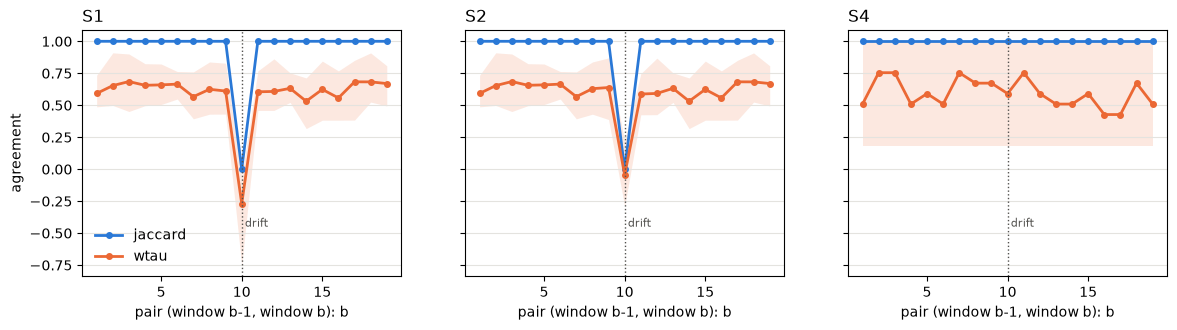

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, name in zip(axes, ["S1", "S2", "S4"]):
    p = pairs[pairs.stream == name]
    for metric, col in (("jaccard", FIRST), ("wtau", LAST)):
        g = p.groupby("win_b")[metric]
        ax.plot(g.mean().index, g.mean().values, "-o", ms=4, lw=2, color=col, label=metric)
        ax.fill_between(g.mean().index, g.min().values, g.max().values, color=col, alpha=0.15, lw=0)
    ax.axvline(10, color=INK2, ls=":", lw=1); ax.text(10.2, -0.45, "drift", color=INK2, fontsize=8)
    ax.set_title(name, loc="left"); ax.set_xlabel("pair (window b-1, window b): b"); ax.grid(axis="y", color=GRID)
axes[0].set_ylabel("agreement"); axes[0].legend(frameon=False)
plt.show()

**What to look for.**
- On S1 and S2, how many consecutive pairs disagree, and where are they? Is the ranking stable *before*
  and *after* the drift?
- Last pre-drift window vs last window: does the top-3 change on S1/S2? Does it stay the same on S4
  (PROTOCOL.md §12 says S4's top-2 set must be identical)?
- Why is weighted τ *negative* when comparing before and after the drift on S1?
- S2's crossing pair has a higher weighted τ than S1's. Why might a gradual drift smear the change across
  windows?

> **Conclusion (section 3: S1, S2 and S4).**
> - **Relevance re-orients to the true features.** On S1 and S2 the top-3 goes from {x0, x1, x2} in the last
>   pre-drift window to {x5, x6, x7} in the last window in 10/10 seeds (Jaccard 0; first vs last also 0).
> - **The ranking changes once, at the drift, and is stable on both sides.** Every consecutive pair that does
>   not overlap the drift has Jaccard 1 (minimum 1.000 in all seeds); only the pair spanning the drift drops to 0.
> - **Weighted τ before vs after is negative (−0.35 ± 0.24 on S1, −0.36 ± 0.18 on S2).** The new relevant
>   features were at the floor before the drift and the old ones are at the floor after it, so the top of
>   the ranking is reversed.
> - **The S4 negative control passes.** The top-2 set {x0, x1} is identical in the last pre-drift window and
>   the last window in 10/10 seeds (Jaccard 1), as PROTOCOL.md §12 requires: a change in the label rule that
>   keeps the same relevant features does not move G. Its wτ (0.67 ± 0.42) only reflects the order among 3 features.
> - **Abrupt vs gradual at the window scale:** both end in the same place. The only difference is the pair
>   spanning the drift: wτ −0.27 on S1 vs −0.04 on S2, because S2's transition mixes both concepts inside
>   those windows and spreads the change out.

## 4. Figure 2b: first vs last window

Made by [figure2b.py](../wf5_windows/figure2b.py). Bars = mean over seeds of each feature's relevance in the
first and last window; whiskers = SD over seeds (Elec2: one run). Grey = truly relevant at the start,
dotted = truly relevant at the end.

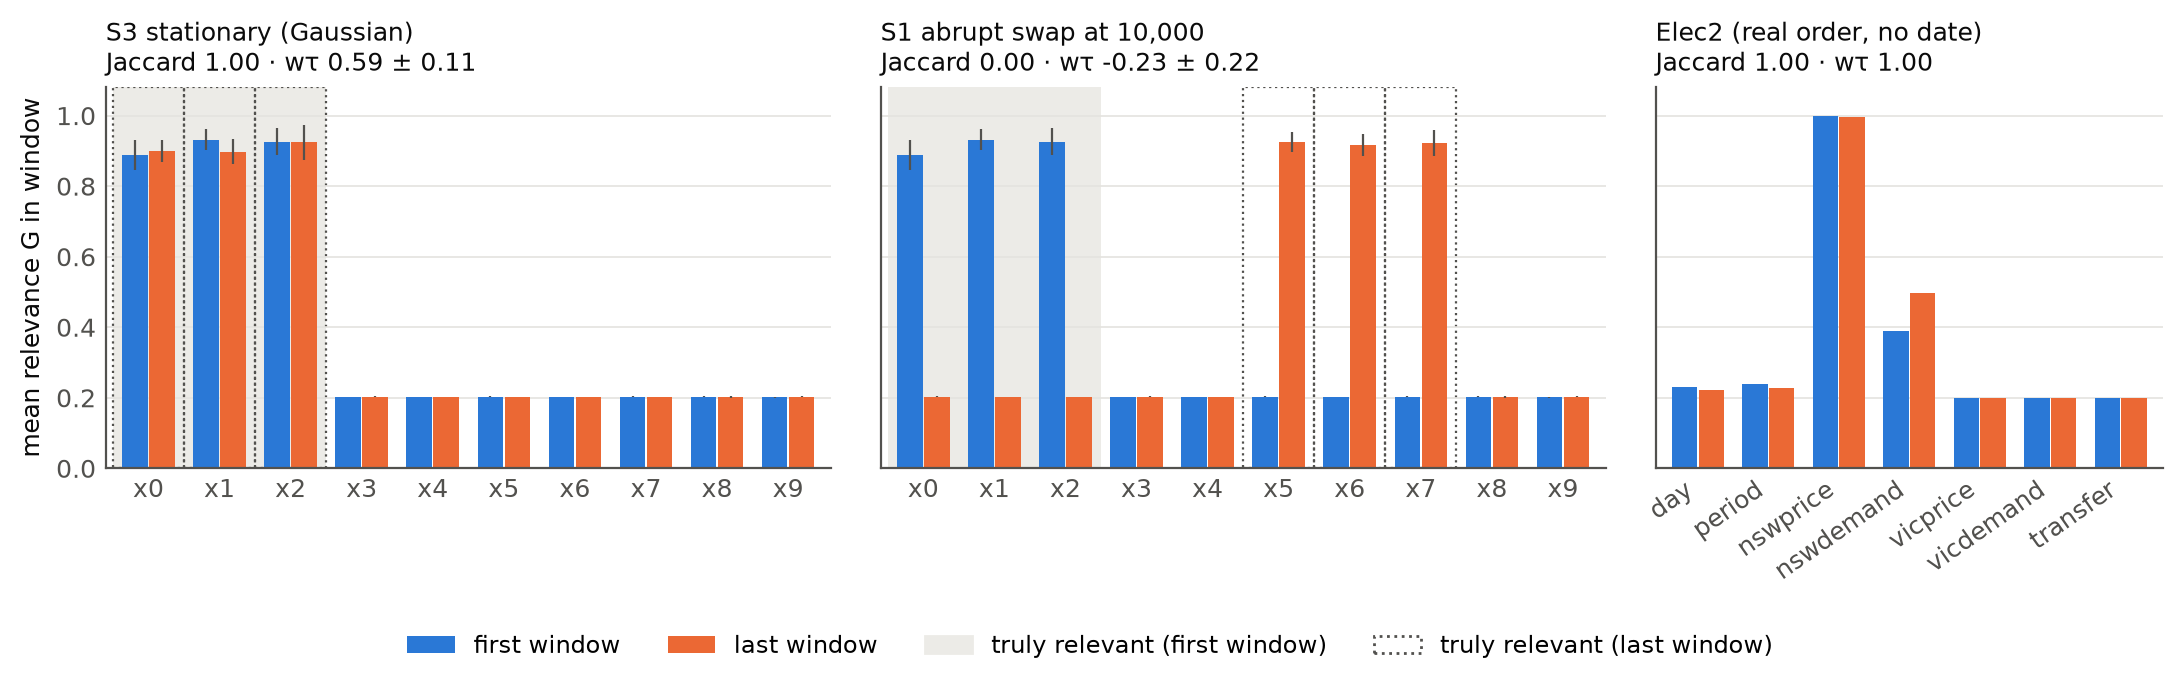

In [7]:
# Re-draw Figure 2b from THIS computer's results before showing it, so the notebook never shows an old or copied PNG.
from wf5_windows import figure2b
figure2b.main()                                   # overwrites wf5_windows/fig2b_first_last_window.png and .pdf
fig_path = ROOT / "wf5_windows" / "fig2b_first_last_window.png"
display(Image(filename=str(fig_path)))

**What to look for.**
- S3: do first and last bars match? Which features sit at the 0.2 floor?
- S1: does the relevance move fully from x0–x2 to x5–x7? Do x0–x2 return to the floor?
- Elec2: which feature dominates? Is the change in `nswdemand` a trend or within-run fluctuation (compare
  with the heat map in 2.2)?
- What single sentence would you put under this figure in the report?

> **Conclusion (Figure 2b).**
> - **Caption for the report:** *Figure 2b. Mean R1 relevance per feature in the first and the last
>   1,000-sample window (mean ± SD over 10 seeds; Elec2: one run). Shaded: truly relevant features at the
>   start; dotted: at the end. On the stationary S3 the relevant features stay on top (top-3 Jaccard 1); on
>   S1 the relevance moves entirely from x0–x2 to x5–x7, matching the ground truth (Jaccard 0); on Elec2
>   `nswprice` dominates both windows and the top-3 is unchanged.*
> - **Main contrast:** S3 and Elec2 have the same top features in their first and last windows, while S1 has
>   a complete swap. G follows the true relevance and nothing else: the old relevant features in S1 fall
>   all the way back to the 0.2 floor.
> - **On Elec2,** the higher `nswdemand` bar in the last window (0.50 vs 0.39) is within-run fluctuation, not
>   a trend: the heat map in 2.2 shows it moving between 0.27 and 0.50 across windows.

## 5. Restabilisation time after drift

s(t) = weighted τ(G at t − 200, G at t). The plot shows s around the drift for one seed of each stream, with
the threshold (10th percentile of clean pre-drift s). The **S3 placebo** applies the same rule to the
stationary stream at a fake drift point (10,000): it shows how often noise alone looks like a drop.

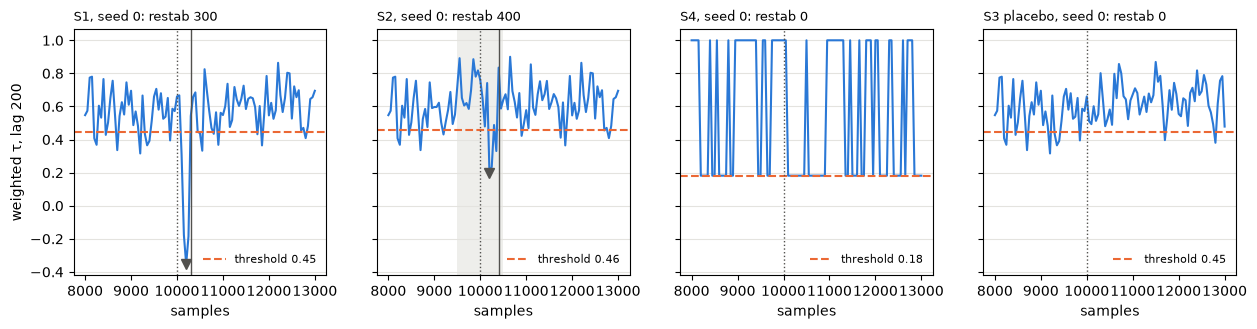

In [8]:
seed = 0
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, name in zip(axes, ["S1", "S2", "S4", "S3"]):
    runs, k, _ = load_runs(name)
    r = [x for x in runs if x["seed"] == seed][0]
    t, s = r["t"], lag_wtau(r["G"], LAG // 50)
    label = "S3 placebo" if name == "S3" else name
    row = restab[(restab.stream.str.startswith(label)) & (restab.seed == seed)].iloc[0]
    m = (t >= 8000) & (t <= 13000)
    ax.plot(t[m], s[m], color=FIRST, lw=1.5)
    ax.axhline(row.threshold, color=LAST, lw=1.5, ls="--", label=f"threshold {row.threshold:.2f}")
    ax.axvline(10000, color=INK2, ls=":", lw=1)
    if name == "S2": ax.axvspan(9500, 10500, color=GRID, alpha=0.6, lw=0)
    if row.dropped:
        ax.plot(row.t_trough, row.trough, "v", color=INK2, ms=7)
        ax.axvline(10000 + row.restab_from_dp, color=INK2, lw=1)
    ax.set_title(f"{label}, seed {seed}: restab {row.restab_from_dp:.0f}", loc="left", fontsize=9)
    ax.set_xlabel("samples"); ax.grid(axis="y", color=GRID); ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_ylabel("weighted τ, lag 200")
plt.show()

Dotted line = drift point; ▼ = trough; solid vertical line = restabilisation; grey band = S2's transition.

### 5.1 Restabilisation per seed
`restab` is counted from the end of the transition (protocol), `restab_from_dp` from the drift point (use
this one to compare S1 with S2). `wf2_ranking_recovery_from_dp` = WF2's time for top-3 precision to return to 1.

In [9]:
show = ["stream", "seed", "threshold", "trough", "t_trough", "dropped", "restab", "restab_from_dp",
        "wf2_ranking_recovery_from_dp"]
display(restab[show].round(3))
summary = restab.groupby("stream", sort=False).agg(
    dropped=("dropped", "sum"), restab_mean=("restab_from_dp", "mean"), restab_sd=("restab_from_dp", "std"),
    trough_mean=("trough", "mean"), wf2_recovery=("wf2_ranking_recovery_from_dp", "mean"))
display(summary.round(2))
d = restab[restab.stream == "S1"]
print("S1: restabilisation minus WF2 ranking recovery =",
      (d.restab_from_dp - d.wf2_ranking_recovery_from_dp).describe()[["mean", "min", "max"]].round(0).to_dict())

,stream,seed,threshold,trough,t_trough,dropped,restab,restab_from_dp,wf2_ranking_recovery_from_dp
0,"S3 placebo (no drift; fake dp 10,000)",0,0.446,0.481,10400.0,False,0.0,0.0,NaN
1,"S3 placebo (no drift; fake dp 10,000)",1,0.453,0.449,10100.0,True,150.0,150.0,NaN
2,"S3 placebo (no drift; fake dp 10,000)",2,0.453,0.335,10700.0,True,850.0,850.0,NaN
3,"S3 placebo (no drift; fake dp 10,000)",3,0.439,0.463,10200.0,False,0.0,0.0,NaN
4,"S3 placebo (no drift; fake dp 10,000)",4,0.442,0.468,10700.0,False,0.0,0.0,NaN
5,"S3 placebo (no drift; fake dp 10,000)",5,0.442,0.477,10600.0,False,0.0,0.0,NaN
6,"S3 placebo (no drift; fake dp 10,000)",6,0.447,0.376,10550.0,True,700.0,700.0,NaN
7,"S3 placebo (no drift; fake dp 10,000)",7,0.446,0.294,10050.0,True,200.0,200.0,NaN
8,"S3 placebo (no drift; fake dp 10,000)",8,0.444,0.449,10500.0,False,0.0,0.0,NaN
9,"S3 placebo (no drift; fake dp 10,000)",9,0.447,0.360,11000.0,True,1050.0,1050.0,NaN


,dropped,restab_mean,restab_sd,trough_mean,wf2_recovery
stream,,,,,
"S3 placebo (no drift; fake dp 10,000)",5,295.0,409.23,0.42,NaN
S1,10,380.0,94.87,-0.33,145.0
S2,10,330.0,48.30,0.15,190.0
S4,0,0.0,0.00,0.18,50.0


S1: restabilisation minus WF2 ranking recovery = {'mean': 235.0, 'min': 150.0, 'max': 450.0}


### 5.2 Paired tests against the placebo
Same seed = same pre-drift data, so S1/S2 and the placebo are paired. Wilcoxon signed-rank, Holm-corrected.

In [10]:
txt = (RES / "table_wf5.md").read_text(encoding="utf-8")
display(Markdown(txt[txt.index("### Paired tests"):]))

### Paired tests against the placebo (same seed = same pre-drift data; Wilcoxon, Holm over these tests)

| Comparison | n | W | p | p (Holm) | rank-biserial |
|---|---|---|---|---|---|
| S1 vs S3 placebo: trough wτ | 10 | 0.0 | 0.0020 | 0.0078 | -1.00 |
| S1 vs S3 placebo: restabilisation from dp | 10 | 20.5 | 0.5020 | 1.0000 | +0.25 |
| S2 vs S3 placebo: trough wτ | 10 | 0.0 | 0.0020 | 0.0078 | -1.00 |
| S2 vs S3 placebo: restabilisation from dp | 10 | 24.0 | 0.7676 | 1.0000 | +0.13 |


**What to look for.**
- How many samples after the drift does S1 restabilise? Compare with WF2's ranking recovery (145). Why is
  restabilisation about 200 samples later? (Hint: s compares G now with G 200 samples ago; when are *both*
  snapshots from the new concept?)
- S2 from the transition end is 50 in every seed. Is that a real result or a floor? Which column should
  be used to compare S1 and S2?
- S4 never drops below the threshold. Is that what a negative control should show?
- The placebo: in how many seeds does noise alone dip below the threshold? Given that, is the
  restabilisation **time** informative on its own? And the **trough** depth?

> **Conclusion (section 5: restabilisation).**
> - **The drift clearly destabilises the ranking.** On S1 weighted τ at lag 200 drops below its pre-drift 10th
>   percentile (≈ 0.45) in 10/10 seeds, with a mean trough of −0.33. On S2 it drops in 10/10 seeds (mean
>   trough 0.15). On S4 it never drops (0/10), as a negative control should.
> - **Restabilisation time, from the drift point:** 380 ± 95 samples on S1 (300–600) and 330 ± 48 on S2.
>   Measured from the end of S2's transition (the protocol convention) it is 50 in every seed. That is a
>   one-checkpoint floor, the same one WF2 found, so S1 and S2 must be compared using the drift-point column.
> - **It lags WF2's ranking recovery by about 200 samples:** 235 on average on S1 (150–450) and 140 on S2.
>   This is expected by construction: weighted τ at lag 200 compares G now with G 200 samples ago, so it is
>   back to normal only when *both* snapshots come from the new concept, i.e. ≈ ranking recovery + 200.
> - **The placebo shows the time is a noisy measure.** On the stationary S3 with a fake drift, noise alone
>   dips below the threshold in 5/10 seeds and "restabilises" after 0–1,050 samples (295 ± 409).
>   - The **trough** separates real drift from noise perfectly: S1 and S2 are lower than the placebo in
>     10/10 seeds (Wilcoxon p = 0.002, Holm p = 0.008, rank-biserial −1).
>   - The **time** does not (p = 0.50 on S1, 0.77 on S2; Holm p = 1.0).
> - **Takeaway:** report the restabilisation time as a secondary, noisy summary, alongside the trough depth
>   and WF2's ranking recovery, which are the informative quantities.

## 6. Overall conclusions and limitations

Things that limit what can be claimed (to discuss):
- Elec2 is one real order, so there is no CI and no ground truth for its relevance.
- Window means average 20 checkpoints, so short fluctuations are hidden (compare with WF1 at lag 200).
- The irrelevant features sit at the 0.2 floor, so weighted τ over all features partly measures noise.
- Restabilisation decisions not fixed by the protocol (trough, placebo, clean checkpoints) are listed in
  PROTOCOL.md §14 as *pending* team approval.

> **Overall conclusion (SQ1 × SQ2).**
> - **Answer:** at the 1,000-sample window scale, R1 is stable when nothing changes and re-orients cleanly
>   when the relevant features change.
>   - Stationary S3 keeps the same top-3 in every window.
>   - S1 and S2 switch completely to the new relevant features at the drift and are stable on both sides.
>   - S4, whose drift does not change which features matter, keeps the same top-2.
>   - Elec2 keeps its two leading features (`nswprice`, `nswdemand`), with churn only at a near-tied third place.
> - **After an abrupt drift** the rank agreement collapses (trough far below anything seen without drift) and
>   is back to its pre-drift level about 380 samples later, roughly WF2's ranking recovery plus the 200-sample lag.
> - **For the progress report:**
>   - Figure 2b with the caption in section 4.
>   - Restabilisation from the drift point: 380 ± 95 (S1) and 330 ± 48 (S2), 0 on S4, with the placebo
>     comparison (trough p = 0.002; time not distinguishable from noise).
> - **Limitations:**
>   - Elec2 is a single order with no ground truth, so it has no CI and its rank-3 churn cannot be
>     separated from noise here.
>   - Window means average 20 checkpoints, so short fluctuations are smoothed out (WF1's lag-200 analysis covers those).
>   - Weighted τ over all features is dominated by the irrelevant features at the 0.2 floor.
>   - With only 3 features, weighted τ on S4 takes few distinct values, so it is a coarse measure there.
>   - The restabilisation choices not fixed in the protocol (trough, placebo, clean checkpoints, the S2
>     pre-drift window) are recorded in PROTOCOL.md §14 as pending team approval.